# Fresh 1% tracking-error standalone results
This notebook uses the standalone and equal-weight results extracted from the final run. Ridge and equal-weight candidates are evaluated only as unrestricted active portfolios; standalone DMD and inflation are also evaluated long-only. Original and residualized DMD use the same stocks. All returns are gross of costs.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
DATA = Path('dataset')
assert DATA.exists(), 'Run from the submission directory'
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top':False, 'axes.spines.right':False})


,portfolio,sessions,active_sharpe,realized_TE,max_predicted_TE,max_abs_beta
0,dmd_standalone_active,3773,0.999628,0.013159,0.01,3.667585e-16
1,dmd_standalone_long_only,3773,0.735455,0.012005,0.01,8.550145e-16
2,equal_weight_active,3773,1.058436,0.013241,0.01,3.681951e-16
3,inflation_standalone_active,3773,0.254573,0.013670,0.01,6.857172e-16
4,inflation_standalone_long_only,3773,0.128722,0.011495,0.01,2.152954e-16
5,original_dmd_matched_active,3773,1.002518,0.013165,0.01,3.094855e-16
6,original_dmd_matched_long_only,3773,0.736261,0.012017,0.01,1.577541e-15


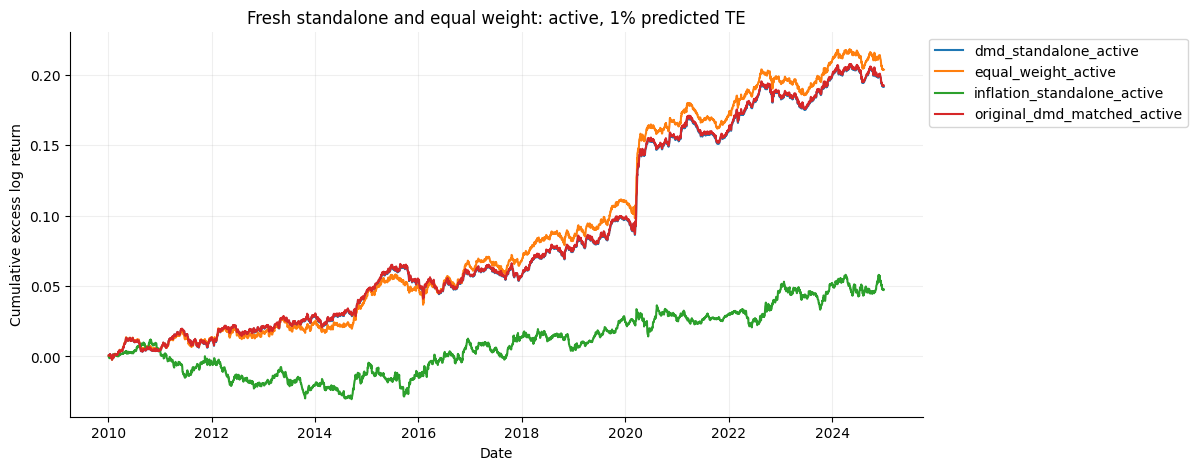

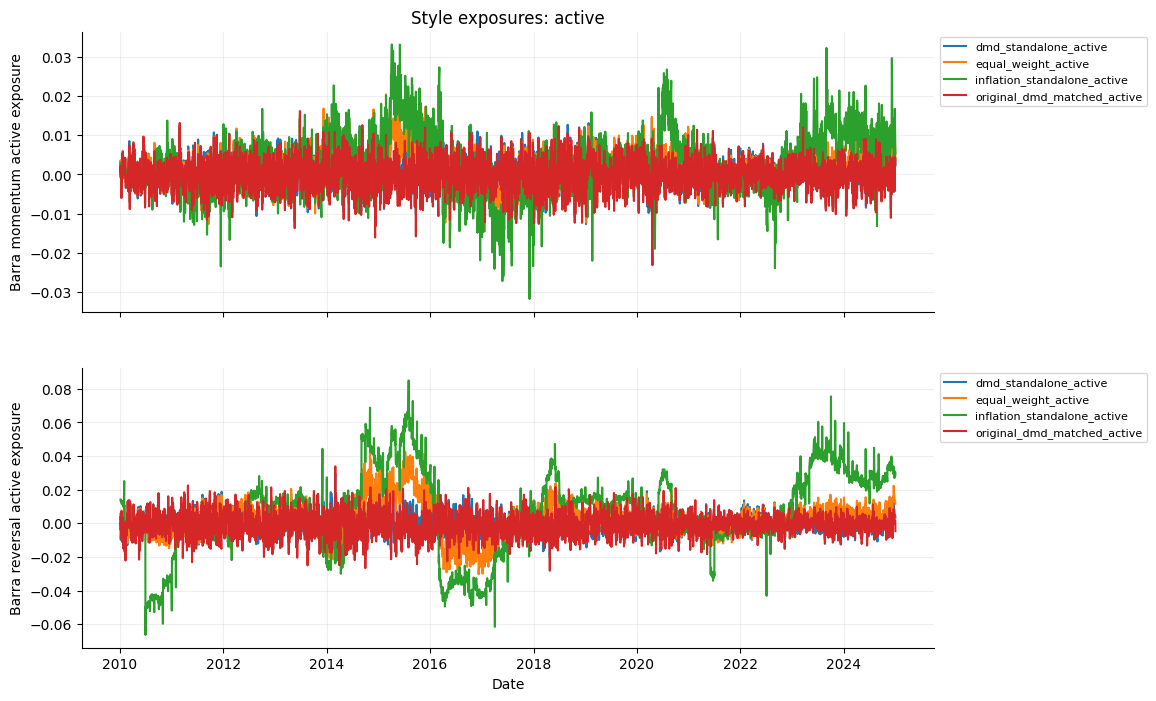

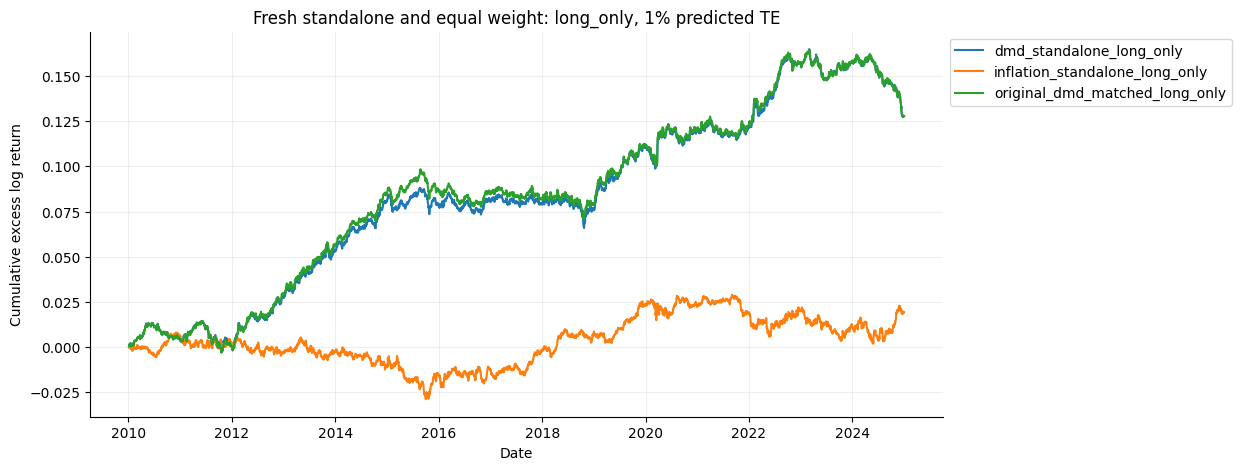

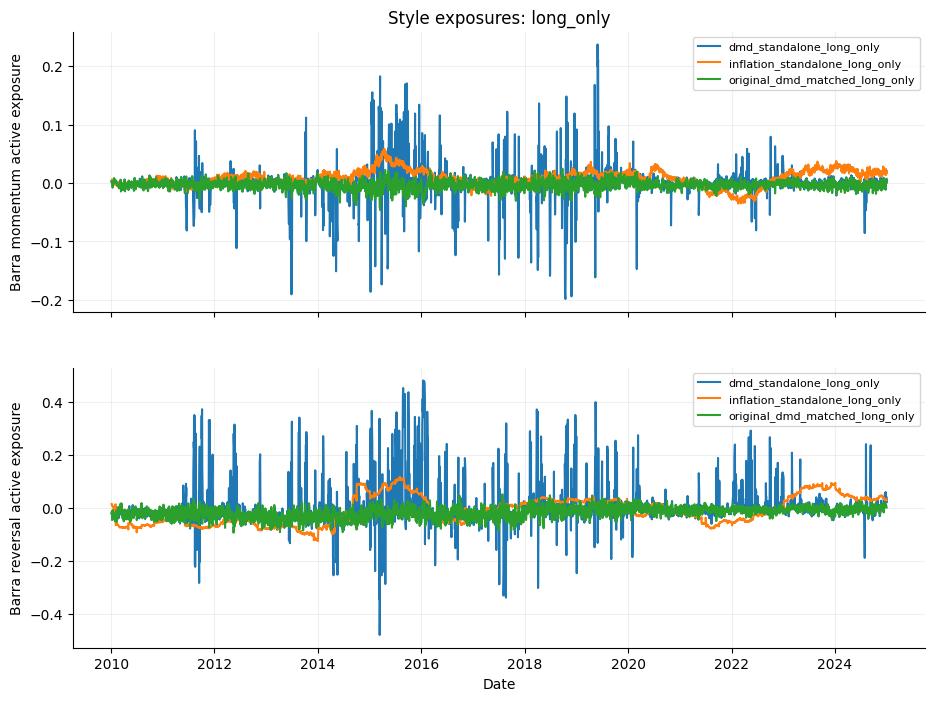

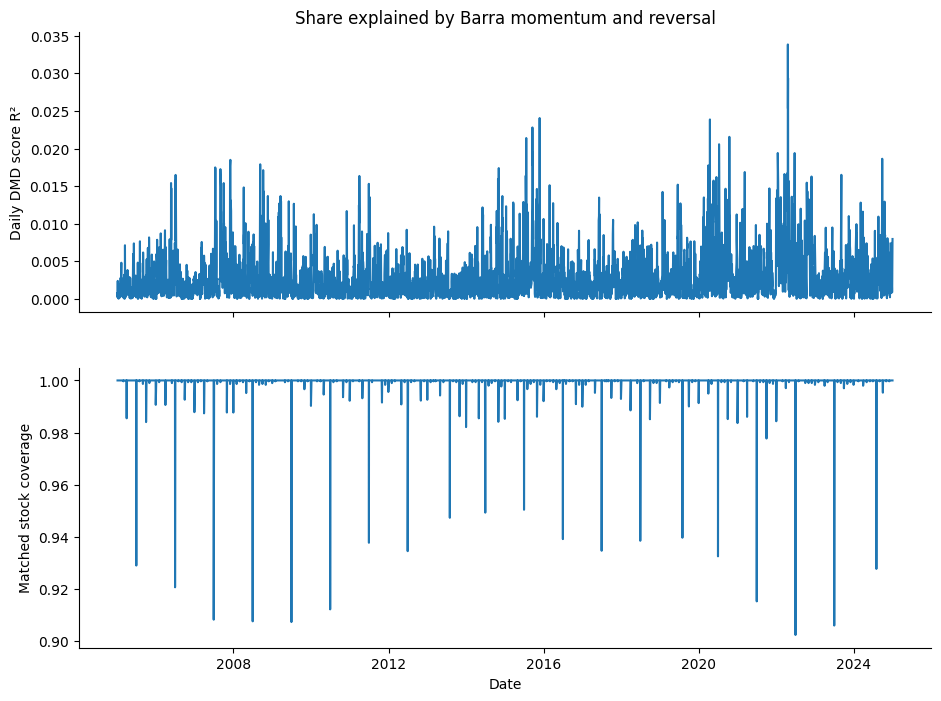

In [2]:
r=pd.read_parquet(DATA/'baseline_returns.parquet').sort_values('date')
f=pd.read_parquet(DATA/'baseline_factor_exposures.parquet')
d=pd.read_parquet(DATA/'style_diagnostics.parquet')
assert r.predicted_te.max()<=.010001
assert r.active_beta.abs().max()<1e-5
assert np.allclose(r.total_investment,1,atol=1e-5)
assert r[r.portfolio.str.endswith('_long_only')].minimum_total_weight.min()>-1e-6
summary=[]
for name,g in r.groupby('portfolio'):
    summary.append({'portfolio':name,'sessions':len(g),'active_sharpe':np.sqrt(252)*g.active_return.mean()/g.active_return.std(),'realized_TE':np.sqrt(252)*g.active_return.std(),'max_predicted_TE':g.predicted_te.max(),'max_abs_beta':g.active_beta.abs().max()})
display(pd.DataFrame(summary).sort_values('portfolio'))
for variant in ['active','long_only']:
    fig,ax=plt.subplots()
    for name,g in r[r.portfolio.str.endswith('_'+variant)].groupby('portfolio'):
        g=g.sort_values('date')
        ax.plot(g.date,(np.log1p(g.portfolio_return)-np.log1p(g.benchmark_return)).cumsum(),label=name)
    ax.set(title=f'Fresh standalone and equal weight: {variant}, 1% predicted TE',ylabel='Cumulative excess log return',xlabel='Date')
    ax.legend(bbox_to_anchor=(1,1));ax.grid(alpha=.2);plt.show()
    fig,axes=plt.subplots(2,1,figsize=(11,8),sharex=True)
    for name,g in r[r.portfolio.str.endswith('_'+variant)].groupby('portfolio'):
        axes[0].plot(g.date,g.lagged_momentum_exposure,label=name)
        axes[1].plot(g.date,g.lagged_reversal_exposure,label=name)
    axes[0].set(ylabel='Barra momentum active exposure',title=f'Style exposures: {variant}')
    axes[1].set(ylabel='Barra reversal active exposure',xlabel='Date')
    for ax in axes: ax.legend(fontsize=8,bbox_to_anchor=(1,1));ax.grid(alpha=.2)
    plt.show()
fig,axes=plt.subplots(2,1,figsize=(11,8),sharex=True)
axes[0].plot(d.date,d.r2);axes[0].set(ylabel='Daily DMD score R²',title='Share explained by Barra momentum and reversal')
axes[1].plot(d.date,d.coverage);axes[1].set(ylabel='Matched stock coverage',xlabel='Date')
plt.show()
